In [1]:
import pyccl as ccl
import numpy as np
import matplotlib.pyplot as plt
from itertools import pairwise

import sys
sys.path.append('../')
from src import load_config, fisher_matrix, redshift_distributions, names_to_latex

## Load configuration

In [2]:
config = load_config('../configs/config_IA_bias.yaml')
config_biased = load_config('../configs/config_noIA.yaml')

## Setup and compute the Fisher matrix

In [3]:
def compute_fisher_matrix(config):
    print(f'Running fisher analysis for {config.name}.')
    # Load the cosmology
    ccl_cosmo_params = dict(zip(config.cosmology.keys(), config.cosmology.values()))
    if 'Omega_m' in ccl_cosmo_params.keys():
        ccl_cosmo_params['Omega_c'] = ccl_cosmo_params['Omega_m'] - ccl_cosmo_params['Omega_b']
        ccl_cosmo_params.pop('Omega_m')
    cosmo = ccl.Cosmology(**ccl_cosmo_params,
                          matter_power_spectrum='camb',
                          extra_parameters = {"camb": config.baryons_dict})

    # ell binning setup
    ell_bins = np.geomspace(config.ell_binning.cosmic_shear.bin_start,
                                config.ell_binning.cosmic_shear.bin_end,
                                config.ell_binning.cosmic_shear.N_bins)
    ell_bins = ell_bins[
        (ell_bins >= config.ell_binning.cosmic_shear.ell_min) &
        (ell_bins <= config.ell_binning.cosmic_shear.ell_max)
        ].astype(int)
    ell_arr = np.array([(a + b) / 2 for a, b in pairwise(ell_bins)]).astype(int)
    Delta_ell = np.array([b - a for a, b in pairwise(ell_bins)])

    # Or your own binning here
    #ell_arr = np.arange(50, 1000)
    #Delta_ell = None

    # Define the forecasting setup
    sigma_e = config.forecast.e_rms  # e-RMS for shape noise.
    N_z_bins = config.redshift_distributions.sources.N_z_bins  # Number of z-bins.
    z_arr = np.linspace(config.forecast.z_min, config.forecast.z_max,
                        config.forecast.N_z_values)
    nz_arr, zbin_edges = (
        redshift_distributions.get_redshift_distributions(
            z_arr, N_z_bins,
            config.redshift_distributions.sources.z0,
            config.redshift_distributions.sources.a,
            config.redshift_distributions.sources.sigma_z))
    # Galaxy number density, if not wanted to be from LSST Y1/Y10
    #config['redshift_distributions']['sources']['nbar'] = 5./(4.*np.pi/(41253.0*60.0*60.0))

    # Define the fisher matrix setup
    cosmo_params = {'name': list(config.cosmology.keys()),
                    'fiducial': list(config.cosmology.values()),
                    'shift': [config.derivatives.step_size[x] for x in list(config.cosmology.keys())],
                    'latex': [names_to_latex(x) for x in config.cosmology.keys()]}
    astro_params = {'name': list(config.IA.keys())+list(config.baryons.keys()),
                    'fiducial': list(config.IA.values())+list(config.baryons.values()),
                    'shift': [config.derivatives.step_size[x] for x in list(config.IA.keys())+list(config.baryons.keys())],
                    'latex': [names_to_latex(x) for x in list(config.IA.keys())+list(config.baryons.keys())]}
    redshift_params = {'name': [f'dz{i+1}' for i in range(N_z_bins)],
                       'fiducial': [0.] * N_z_bins,
                       'shift': [config.derivatives.step_size.delta_z] * N_z_bins,
                       'latex': [r'$\Delta z_{%i}$' % (i + 1) for i in range(N_z_bins)]}

    # Compute the fisher matrix
    print(f'Computing fisher matrix.')
    fm = fisher_matrix(cosmo=cosmo, z=z_arr, dndz=nz_arr, ell=ell_arr,
                       sigma_e=sigma_e,
                       n_bar=config.redshift_distributions.sources.nbar,
                       fsky=config.forecast.fsky, Delta_ell=Delta_ell,
                       n_points=config.derivatives.stencil_points, cosmo_params=cosmo_params,
                       astro_params=astro_params, redshift_params=redshift_params)
    # Add Gaussian photo-z priors
    mean_z = np.trapezoid(nz_arr * z_arr, z_arr)
    scale_z = config.redshift_distributions.sources.sigma_delta_z*(1+mean_z)
    fm.add_prior(redshift_params['name'], scale_z)
    return fm

In [4]:
fm = compute_fisher_matrix(config)
fm_fixed = fm.fix_parameters('A_IA')

fmS8 = fm.transform_A_s_to_S8()
fmS8_fixed = fmS8.fix_parameters('A_IA')
fmS8_marginalised = fmS8.marginalise(['Omega_m', 'S8', 'A_IA'])
fmS8_marginalised_fixed = fmS8_fixed.marginalise(['Omega_m', 'S8'])

Running fisher analysis for IA.
Computing fisher matrix.


## Fisher bias 
#### Compute the Fisher matrix without IA

In [5]:
fm_noIA = compute_fisher_matrix(config_biased)

fmS8_noIA = fm_noIA.transform_A_s_to_S8()
fmS8_noIA_marginalised = fmS8_noIA.marginalise(['Omega_m', 'S8'])

Running fisher analysis for noIA.
Computing fisher matrix.


#### Get the systematics $C_\ell$.

In [6]:
C_ell_sys = dict()
for key in fm.C_ell.keys():
    C_ell_sys[key] = fm.C_ell[key] - fm_noIA.C_ell[key]

#### Obtain the Fisher bias, using the assumed, biased model (without IA).
$$
b(\theta_i)=(F^{-1})_{ij}\sum_\ell \left( C_\ell^{\rm true}-C_\ell^{\rm model}\right)C_A^{-1}\left( \frac{{\rm d} C_\ell^{\rm model}}{{\rm d} \theta_j} \right)
$$
but is it dCmodel or dCtrue? I think dCtrue! What Fisher matrix are we using? It's the chi-square but with $\hat{C}_\ell=C_\ell^{\rm m}+C_\ell^{\rm s}+C_\ell^{\rm n}$.

In [7]:
N_params = fm_noIA.dim

bias_j = np.zeros(N_params)
for l in range(fm.data_covariance.shape[0]):
    C_ell_sys_at_ell = np.array(list(C_ell_sys.values()))[:,l]
    invcov = np.linalg.inv(fm.data_covariance[l])
    bias_j += (C_ell_sys_at_ell.dot(invcov)).dot(fm_fixed.d_C_ell[l, :, :].T)

bias = fm_fixed.covariance.dot(bias_j)

for ip, p in enumerate(fm_noIA.parameters):
    print(f'{p} bias: {bias[ip]}')

Omega_m bias: -0.018863231357950518
h bias: 0.08525639643110013
A_s bias: -1.988986331972291e-10
n_s bias: -0.0544219510129519


## Compute the bias assuming a $\delta A_\mathrm{IA}$
Compute the expected bias
$$
(\delta\theta) = (F_{\theta\theta})^{-1}\,\left(F_{\theta,A_\mathrm{IA}}\right)^\mathrm{T}\,\delta A_\mathrm{IA}
$$
where the fisher matrix $F_{\theta\theta}$ is the matrix by fixing the systematics parameters and $F_{\theta,A_\mathrm{IA}}$ is a vector with the elements in the fisher matrix corresponding to $\theta$ and $A_\mathrm{IA}$. 

In [8]:
f_theta_AIA = np.array([fm[p, 'A_IA'][0,1] for p in fm_fixed.parameters])

delta_theta = fm_fixed.covariance.dot(f_theta_AIA)*fm.A_IA

for ip, p in enumerate(fm_noIA.parameters):
    print(f'{p} bias: {delta_theta[ip]}')

Omega_m bias: -0.0187922493750598
h bias: 0.08505687210377538
A_s bias: -1.9849515763225336e-10
n_s bias: -0.05443806886258904


### Plot the bias:

In [9]:
biased_centers_amara = fm_fixed.fiducial_parameters+bias
biased_centers = fm_fixed.fiducial_parameters+delta_theta

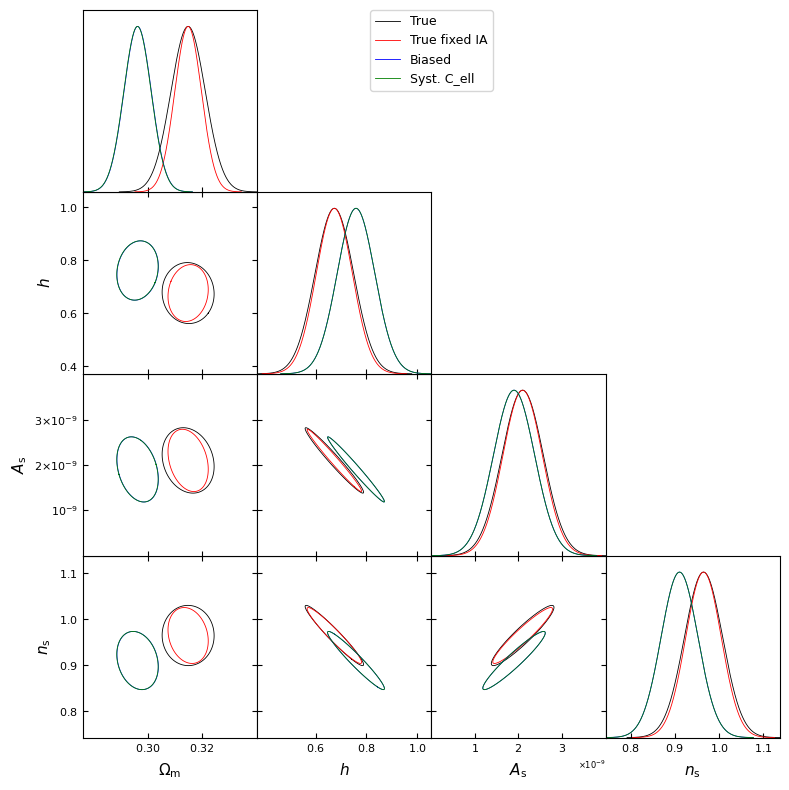

In [10]:
from getdist import plots, MCSamples
from getdist.gaussian_mixtures import GaussianND

f_true = GaussianND(fm_fixed.fiducial_parameters.astype(float), fm.marginalised_covariance(fm_fixed.parameters),
                    labels=[x.strip('$') for x in fm_fixed.latex_parameters],
                    names=fm_fixed.parameters,
                    label='True')
f_fixed = GaussianND(fm_fixed.fiducial_parameters.astype(float), fm_noIA.covariance,
                     labels=[x.strip('$') for x in fm_fixed.latex_parameters],
                     names=fm_fixed.parameters,
                     label='True fixed IA')
f_biased = GaussianND(biased_centers.astype(float),
                      fm_fixed.covariance,
                      #fm.marginalised_covariance(fm_fixed.parameters),
                      labels=[x.strip('$') for x in fm_fixed.latex_parameters],
                      names=fm_fixed.parameters,
                      label='Biased')
f_biased_syst = GaussianND(biased_centers_amara.astype(float),
                           fm_fixed.covariance,
                           #fm.marginalised_covariance(fm_fixed.parameters),
                           labels=[x.strip('$') for x in fm_fixed.latex_parameters],
                           names=fm_fixed.parameters,
                           label='Syst. C_ell')

# Triangle plot
g = plots.get_subplot_plotter()
#g.settings.legend_fontsize = 24
#g.settings.axes_labelsize = 24
#g.settings.axes_fontsize = 20
g.settings.num_plot_contours = 1
g.triangle_plot([f_true, f_fixed, f_biased, f_biased_syst], filled=False)

# Compare to the likelihood sampling

In [11]:
from nautilus import Prior, Sampler
from scipy.stats import norm

filename = '../validation/IA_bias_validation.hdf5'

# Priors
prior = Prior()

for ip, p in enumerate(config.sampling_validation.keys()):
    if config.sampling_validation[p] is None:
        continue
    elif p=='delta_z':
        for i in range(config.redshift_distributions.sources.N_z_bins):
            prior.add_parameter(f'dz_{i + 1}', dist=norm(loc=0.0,
                scale=fm.priors[1][i]))
    elif len(config.sampling_validation[p]) == 2:
        prior.add_parameter(p, dist=tuple(config.sampling_validation[p]))
    else:
        raise ValueError(f'Input parameter in config file had problem: {p}')

sampler = Sampler(prior, lambda x: 1., filepath=filename)

#points, log_w, log_l = sampler.posterior()
points, log_w, log_l, blobs = sampler.posterior(return_blobs=True)
ndim = points.shape[1]

resized_points = points.copy()
resized_points[:,2] *= 1e-9
gd_samples_nautilus = MCSamples(samples=resized_points,
                                weights=np.exp(log_w),
                                loglikes=log_l,
                                names = fm_noIA.parameters,
                                labels = [x.strip('$') for x in fm_noIA.latex_parameters],
                                label='Nautilus',
                                sampler='nested')

S8 = blobs["S8"]
sigma8 = S8*np.sqrt(0.3/points[:,0])
#points_with_S8 = np.column_stack((points, S8))
points_with_S8 = points.copy()
points_with_S8[:, list(fmS8_noIA.parameters).index("S8")] = S8
#points_with_sigma8[:, list(fm.parameters).index("sigma8")] = sigma8

gd_samples_nautilus_S8 = MCSamples(
    samples=points_with_S8,
    weights=np.exp(log_w),
    loglikes=log_l,
    names=fmS8_noIA.parameters,
    labels=[x.strip('$') for x in fmS8_noIA.latex_parameters],
    label='Nautilus',
    sampler='nested'
)

Removed no burn in
Removed no burn in


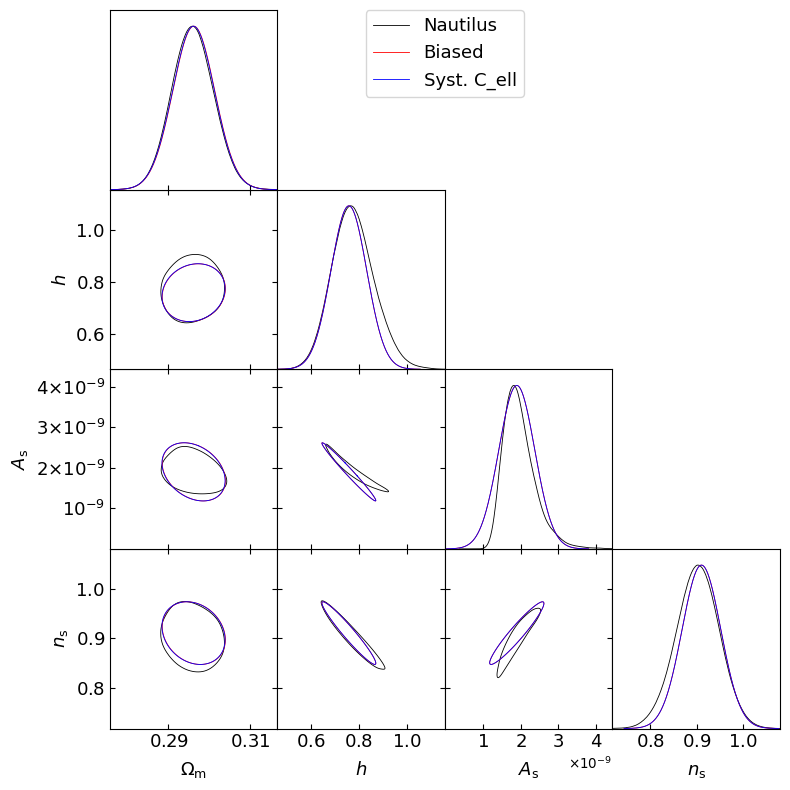

In [12]:
# Triangle plot
g = plots.get_subplot_plotter()

g.settings.legend_fontsize = 16
g.settings.axes_labelsize = 16
g.settings.axes_fontsize = 16
g.settings.num_plot_contours = 1
g.triangle_plot([gd_samples_nautilus, f_biased, f_biased_syst], filled=False)
#g.export('../output/DESC_vanilla_validation.pdf')

# Find the maximum a posteriori
### Using the Mean Shift clustering method

In [13]:
from sklearn.cluster import MeanShift

# Fit Mean Shift to find modes
ms = MeanShift()
ms.fit(resized_points)

# The mode with the highest density
mode = ms.cluster_centers_[0]
print("Maximum density mode:", mode)

Maximum density mode: [2.95864746e-01 7.73038816e-01 1.92416072e-09 9.03306321e-01]


### Using the Nelder-Mead optimisation method

In [14]:
import numpy as np
from scipy.optimize import minimize
from scipy.stats import gaussian_kde


num_dimensions = resized_points.shape[1]

# Normalise the weights
weights_norm = 10**log_w / np.sum(10**log_w)

# Construct weighted KDE
kde = gaussian_kde(
    resized_points.T,
    weights=weights_norm
)

# Define the objective function
def objective(x):
    return -kde(x)

# Initial guess: Mean of the sampled points
initial_guess = resized_points.mean(axis=0)

# Perform Nelder-Mead optimization
result = minimize(objective, initial_guess, method='Nelder-Mead')

# Location of the maximum
max_point_ND = result.x

print(f"Maximum density point: {max_point_ND}")

Maximum density point: [2.95759914e-01 7.59094431e-01 1.98506235e-09 9.12466271e-01]


#### Bias obtained from nested sampling

In [15]:
for ip, p in enumerate(fm_fixed.parameters):
    print(f'Bias from NS for {p}: {max_point_ND[ip] - fm_fixed.fiducial_parameters[ip]}')

Bias from NS for Omega_m: -0.019240085982659416
Bias from NS for h: 0.08509443092027158
Bias from NS for A_s: -1.1383765141838621e-10
Bias from NS for n_s: -0.05253372878891949


# Invert the Fisher bias and obtain the input $A_{\mathrm{IA}}$

In [16]:
# What I expect to get:
print((fm_fixed.fisher_matrix @ delta_theta) / f_theta_AIA)
# What I get using the nested sampling best fit:
print((fm_fixed.fisher_matrix @ (max_point_ND - fm_fixed.fiducial_parameters)) / f_theta_AIA)

[0.1 0.1 0.1 0.1]
[-0.704357398102822 -0.7557058470291881 -0.7680321638434199
 -0.6745057818085632]


In [17]:
for ip, p in enumerate(fm_fixed.parameters):
    if p=='A_s': multiply = 1e+9
    else: multiply = 1.
    print(f'{p} nested sampling bias: {multiply*(max_point_ND-fm_fixed.fiducial_parameters)[ip]:.4f}')
    print(f'{p} Fisher bias: {multiply*delta_theta[ip]:.4f}')

Omega_m nested sampling bias: -0.0192
Omega_m Fisher bias: -0.0188
h nested sampling bias: 0.0851
h Fisher bias: 0.0851
A_s nested sampling bias: -0.1138
A_s Fisher bias: -0.1985
n_s nested sampling bias: -0.0525
n_s Fisher bias: -0.0544


# Compare to changing $A_s$ to $S_8$
### Compute bias and plot

In [18]:
fS8_theta_AIA = np.array([fmS8[p, 'A_IA'][0,1] for p in fmS8_fixed.parameters])

delta_theta_S8 = fmS8_fixed.covariance.dot(fS8_theta_AIA)*fmS8.A_IA

for ip, p in enumerate(fmS8_fixed.parameters):
    print(f'{p} bias: {delta_theta_S8[ip]}')

fmS8_biased_parameters = fmS8_fixed.fiducial_parameters+delta_theta_S8

Omega_m bias: -0.018792249375060383
h bias: 0.08505687210367298
S8 bias: -0.000682068312335426
n_s bias: -0.0544380688625329


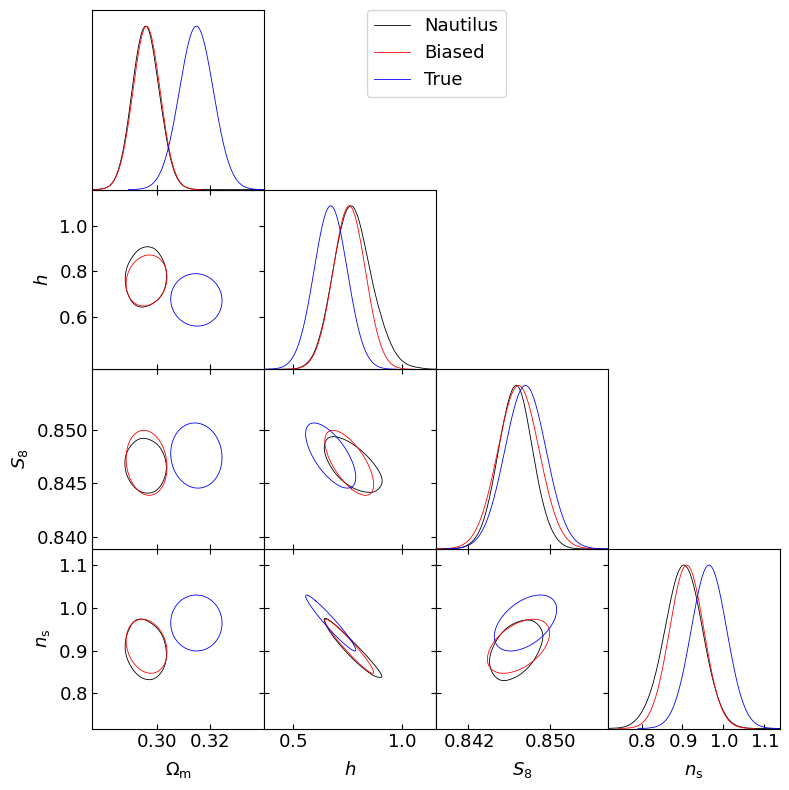

In [19]:
fS8_true = GaussianND(fmS8_fixed.fiducial_parameters.astype(float), fmS8.marginalised_covariance(fmS8_fixed.parameters),
                      labels=[x.strip('$') for x in fmS8_fixed.latex_parameters],
                      names=fmS8_fixed.parameters,
                      label='True')
fS8_fixed = GaussianND(fmS8_fixed.fiducial_parameters.astype(float), fmS8_noIA.covariance,
                       labels=[x.strip('$') for x in fmS8_fixed.latex_parameters],
                       names=fmS8_fixed.parameters,
                       label='True fixed IA')
fS8_biased = GaussianND(fmS8_biased_parameters.astype(float),
                        fmS8_fixed.covariance,
                        #fmS8.marginalised_covariance(fmS8_fixed.parameters),
                        labels=[x.strip('$') for x in fmS8_fixed.latex_parameters],
                        names=fmS8_fixed.parameters,
                        label='Biased')

# Triangle plot
g = plots.get_subplot_plotter()

g.settings.legend_fontsize = 16
g.settings.axes_labelsize = 16
g.settings.axes_fontsize = 16
g.settings.num_plot_contours = 1
g.triangle_plot([gd_samples_nautilus_S8, fS8_biased, fS8_true])
#g.export('../output/DESC_vanilla_validation.pdf')

### Compute S8-transformed and marginalised bias

In [20]:
fS8_marginalised_theta_AIA = np.array([fmS8_marginalised[p, 'A_IA'][0,1] for p in fmS8_marginalised_fixed.parameters])

delta_theta_S8_marginalised = fmS8_marginalised_fixed.covariance.dot(fS8_marginalised_theta_AIA)*fmS8_marginalised_fixed.A_IA

for ip, p in enumerate(fmS8_marginalised_fixed.parameters):
    print(f'{p} bias: {delta_theta_S8_marginalised[ip]}')

fmS8_marginalised_biased_parameters = fmS8_marginalised_fixed.fiducial_parameters+delta_theta_S8_marginalised

# FIXME: This is just plucked out of the previous, unmarginalised result. Why?
print(fmS8_marginalised_biased_parameters-fmS8_biased_parameters[[0,2]])

Omega_m bias: -0.018792249375060542
S8 bias: -0.0006820683123354364
[-1.6653345369377348e-16 0.0]


### Find Nautilus best fit in marginalised $\Omega_m$ - $S_8$ plane

In [21]:
marginalised_points = points_with_S8[:, np.where(np.isin(fmS8_fixed.parameters, ['Omega_m' , 'S8']))[0]]
num_dimensions = marginalised_points.shape[1]

# Construct weighted KDE
kde = gaussian_kde(
    marginalised_points.T,
    weights=weights_norm
)

# Define the objective function
def objective(x):
    return -np.log(max(kde(x)[0], 1e-300))

# Initial guess: Mean of the sampled points
initial_guess = np.average(marginalised_points, weights=weights_norm, axis=0)

# Perform Nelder-Mead optimization
result = minimize(objective, initial_guess, method='Nelder-Mead')

# Location of the maximum
max_point_ND = result.x

print(f"Maximum density point: {max_point_ND}")

Maximum density point: [0.29589852 0.8464701 ]


### Invert the bias equation and get $A_{\mathrm{IA}}$

In [22]:
# What I expect to get:
print('Expectation from Fisher bias equation: ',
      (fmS8_marginalised_fixed.fisher_matrix @ delta_theta_S8_marginalised) / fS8_marginalised_theta_AIA)

# What I get using the nested sampling best fit:
print('Inferred from Nautilus best fit:',
      (fmS8_marginalised_fixed.fisher_matrix @ (max_point_ND-fmS8_marginalised_fixed.fiducial_parameters)) / fS8_marginalised_theta_AIA)

Expectation from Fisher bias equation:  [0.1 0.1]
Inferred from Nautilus best fit: [0.10239298817610748 0.12729275129916473]


### Sensitivity to Natulus vs Fisher $\delta\theta$

In [23]:
# Get ranges of bias in Omega_m and S8
sigma_theta = np.diag(fmS8_marginalised_fixed.covariance)**0.5

Om_biases = np.linspace(delta_theta_S8_marginalised[0]-0.3*sigma_theta[0], delta_theta_S8_marginalised[0]+0.3*sigma_theta[0], 100)
S8_biases = np.linspace(delta_theta_S8_marginalised[1]-0.3*sigma_theta[1], delta_theta_S8_marginalised[1]+0.3*sigma_theta[1], 100)

In [24]:
# Get arrays with fixed S8 bias and varying Omega_m bias, and vice versa:
delta_Om_fisher = np.vstack([
    Om_biases,
    np.full(len(Om_biases), delta_theta_S8_marginalised[np.where(np.isin(fmS8_marginalised_fixed.parameters, 'S8'))][0])
])

delta_S8_fisher = np.vstack([
    np.full(len(S8_biases), delta_theta_S8_marginalised[np.where(np.isin(fmS8_marginalised_fixed.parameters, 'Omega_m'))][0]),
    S8_biases
])

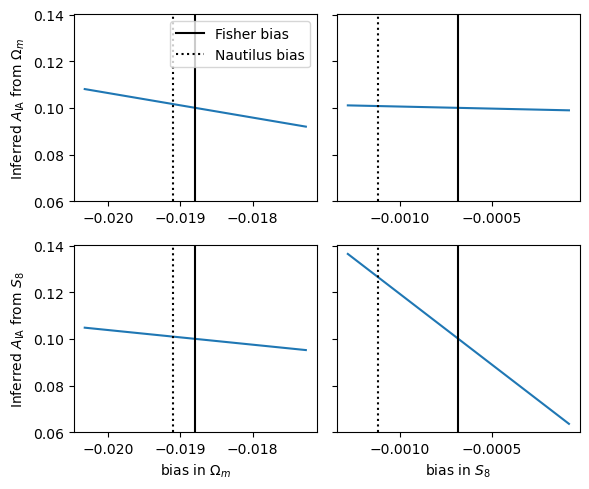

In [25]:
# Compute what the Fisher bias equation would infer for IA for all these different Omega_m - S8 bias scenarios:
deltapsi_Om_inferred = (fmS8_marginalised_fixed.fisher_matrix @ (delta_Om_fisher)) / fS8_marginalised_theta_AIA[:, None]
deltapsi_S8_inferred = (fmS8_marginalised_fixed.fisher_matrix @ (delta_S8_fisher)) / fS8_marginalised_theta_AIA[:, None]

fig, ax = plt.subplots(2, 2, figsize=(6,5), sharex=False, sharey=True, layout='tight')

ax[0,0].plot(Om_biases, deltapsi_Om_inferred[0])
ax[1,0].plot(Om_biases, deltapsi_Om_inferred[1])
for a in ax[:,0]:
    a.axvline(delta_theta_S8_marginalised[0], color='k', label='Fisher bias')
    a.axvline((max_point_ND-fmS8_marginalised_fixed.fiducial_parameters)[0], color='k', ls=':', label='Nautilus bias')
ax[0,0].set_ylabel(r'Inferred $A_\mathrm{IA}$ from $\Omega_m$')
ax[1,0].set_ylabel(r'Inferred $A_\mathrm{IA}$ from $S_8$')

ax[0,1].plot(S8_biases, deltapsi_S8_inferred[0])
ax[1,1].plot(S8_biases, deltapsi_S8_inferred[1])
for a in ax[:,1]:
    a.axvline(delta_theta_S8_marginalised[1], color='k', label='Fisher bias')
    a.axvline((max_point_ND-fmS8_marginalised_fixed.fiducial_parameters)[1], color='k', ls=':', label='Nautilus bias')

ax[-1,0].set_xlabel(r'bias in $\Omega_m$')
ax[-1,1].set_xlabel(r'bias in $S_8$')
ax[0,0].legend()